<a href="https://colab.research.google.com/github/nirajan-sah/ML/blob/Pytorch/ComputerVision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
from torch import nn

import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor

import matplotlib.pyplot as plt

In [ ]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    transform=ToTensor(),
    download=True
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 175kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.29MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.9MB/s]


In [ ]:
image, label = train_data[0]

In [ ]:
image.shape

torch.Size([1, 28, 28])

In [ ]:
len(train_data.data), len(test_data.data), len(test_data.targets)

(60000, 10000, 10000)

In [ ]:
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

Image shape: torch.Size([1, 28, 28])
Image after squeezing: torch.Size([28, 28])


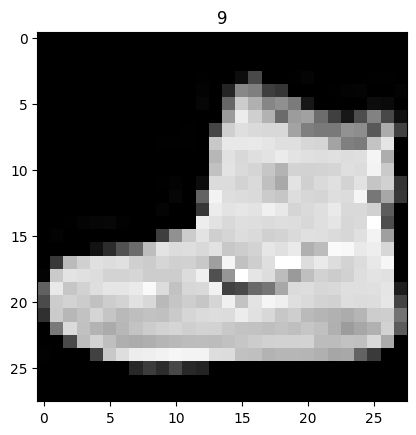

In [ ]:
image, label = train_data[0]
print(f"Image shape: {image.shape}")
print(f"Image after squeezing: {image.squeeze().shape}")
plt.imshow(image.squeeze(), cmap='gist_gray')
plt.title(label)
plt.show()

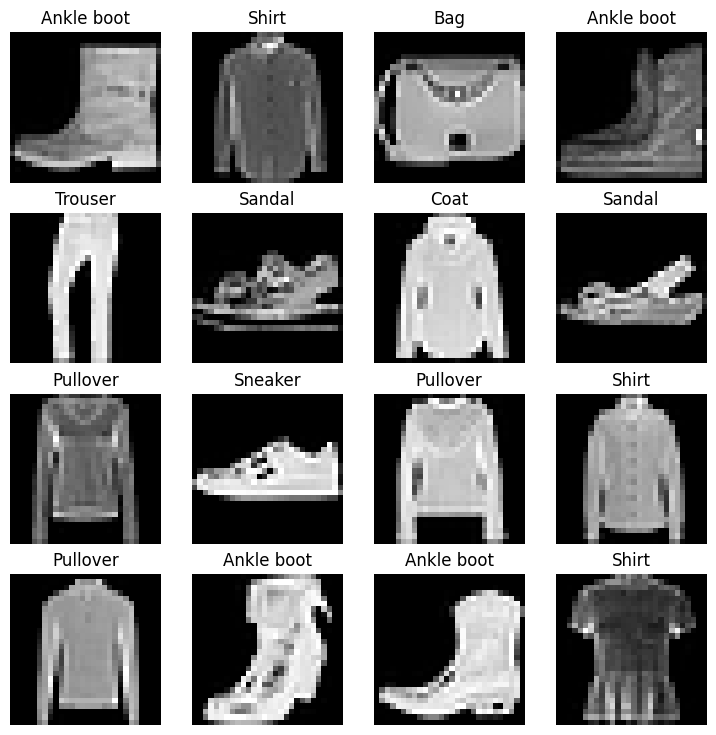

In [ ]:
# Plot more images
torch.manual_seed(42)
fig = plt.figure(figsize=(9, 9))
rows, cols = 4, 4
for i in range(1, rows*cols+1):
  random_idx = torch.randint(0, len(train_data), size=[1]).item()
  image, label = train_data[random_idx]
  fig.add_subplot(rows, cols, i)
  plt.title(class_names[label])
  plt.imshow(image.squeeze(), cmap='gray')
  plt.axis(False)

In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_dataloader = DataLoader(train_data,
                              batch_size=BATCH_SIZE,
                              shuffle=True)
test_dataloader = DataLoader(test_data,
                             batch_size=BATCH_SIZE,
                             shuffle=False)

In [ ]:
print(f"Train Dataloader: {train_dataloader}",
      f"Test Dataloader: {test_dataloader}",
      f"Length of Train Dataloader: {len(train_dataloader)}",
      f"Length of Test Dataloader: {len(test_dataloader)}"
      f"Both has the Batch size of: {BATCH_SIZE}", sep="\n")


Train Dataloader: <torch.utils.data.dataloader.DataLoader object at 0x7f8e93f3e660>
Test Dataloader: <torch.utils.data.dataloader.DataLoader object at 0x7f8e91252490>
Length of Train Dataloader: 1875
Length of Test Dataloader: 313Both has the Batch size of: 32


In [ ]:
train_feature_batch, train_label_batch = next(iter(train_dataloader))
train_feature_batch.shape, train_label_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

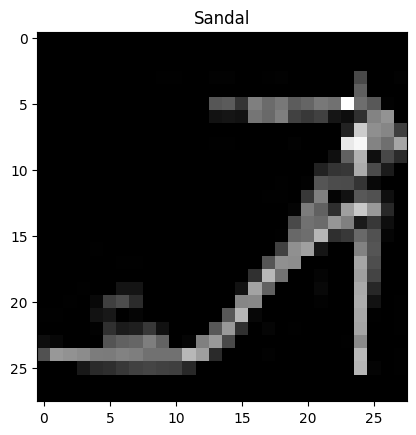

In [ ]:
plt.imshow(train_feature_batch[0].squeeze(), cmap="gray")
plt.title(class_names[train_label_batch[0]])
plt.show()

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
class FashionMNISTModel(nn.Module):
  def __init__(self,
               input_shape: int,
               hidden_shape: int,
               output_shape: int
               ):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape, out_features=hidden_shape),
        nn.Linear(in_features=hidden_shape, out_features=output_shape)
    )

  def forward(self, x):
    return self.layer_stack(x)

In [ ]:
model_0 = FashionMNISTModel(input_shape=784,
                            hidden_shape=10,
                            output_shape=len(class_names)).to(device)

In [ ]:
model_0.state_dict()

OrderedDict([('layer_stack.1.weight',
              tensor([[-0.0165, -0.0042, -0.0145,  ...,  0.0142, -0.0319,  0.0206],
                      [-0.0111, -0.0272,  0.0052,  ...,  0.0217,  0.0023,  0.0029],
                      [ 0.0097,  0.0272, -0.0169,  ...,  0.0310,  0.0307, -0.0014],
                      ...,
                      [ 0.0269, -0.0101, -0.0093,  ..., -0.0008, -0.0126, -0.0139],
                      [-0.0208, -0.0275,  0.0082,  ...,  0.0066,  0.0330,  0.0033],
                      [ 0.0030, -0.0047, -0.0345,  ..., -0.0120,  0.0228,  0.0321]],
                     device='cuda:0')),
             ('layer_stack.1.bias',
              tensor([-0.0169,  0.0152, -0.0084,  0.0227, -0.0054, -0.0284, -0.0354, -0.0013,
                       0.0105, -0.0211], device='cuda:0')),
             ('layer_stack.2.weight',
              tensor([[ 0.2488,  0.1500,  0.1907,  0.1457, -0.3050, -0.0580,  0.1643,  0.1565,
                       -0.2877, -0.1792],
                      [ 0

In [ ]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  # Note: you need the "raw" GitHub URL for this to work
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

In [ ]:
from helper_functions import accuracy_fn # Note: could also use torchmetrics.Accuracy(task = 'multiclass', num_classes=len(class_names)).to(device)

# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss() # this is also called "criterion"/"cost function" in some places
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)

In [ ]:
from timeit import default_timer as timer
def print_train_time(start: float, end: float, device: torch.device = None):
  total_time = end - start
  print(f"Train time on {device} is {total_time:.2f} seconds")
  return total_time

In [ ]:
from tqdm.auto import tqdm

torch.manual_seed(42)
train_time_start_on_cpu = timer()

epochs = 5

for epoch in tqdm(range(epochs)):
  ##Training loop
  print(f"Epoch: {epoch}\n-------")
  train_loss, train_acc = 0, 0
  for batch, (X, y) in enumerate(train_dataloader):
    model_0.train()
    X, y = X.to(device), y.to(device)
    y_preds = model_0(X)

    loss = loss_fn(y_preds, y)

    train_loss += loss
    train_acc += accuracy_fn(y_true=y, y_pred=y_preds.argmax(dim=1))

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    if batch % 400 == 0:
      print(f"Looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples.")

  train_loss /= len(train_dataloader)
  train_acc /= len(train_dataloader)

  ## Testing loop
  test_loss, test_acc = 0, 0
  model_0.eval()

  with torch.inference_mode():
    for X_test, y_test in test_dataloader:
      X_test, y_test = X_test.to(device), y_test.to(device)
      test_pred = model_0(X_test)

      test_loss += loss_fn(test_pred, y_test)
      test_acc += accuracy_fn(y_true=y_test, y_pred=test_pred.argmax(dim=1))

    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)
  print(f"Train loss:{train_loss:.5f} | Train Accuracy:{train_acc:.3f}% | Test loss:{test_loss:.5f} | Test Accuracy:{test_acc:3f}%")

train_time_end_on_cpu = timer()
total_train_time_model_0 = print_train_time(start = train_time_start_on_cpu,
                                            end = train_time_end_on_cpu,
                                            device = str(next(model_0.parameters()).device))


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 0
-------
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train loss:0.89017 | Train Accuracy:71.907% | Test loss:0.62859 | Test Accuracy:78.184904%
Epoch: 1
-------
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train loss:0.56243 | Train Accuracy:80.717% | Test loss:0.54622 | Test Accuracy:80.940495%
Epoch: 2
-------
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train loss:0.50656 | Train Accuracy:82.515% | Test loss:0.51388 | Test Accuracy:82.038738%
Epoch: 3
-------
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.
Train loss:0.47854 | Train Accuracy:83.447% | Test loss

In [ ]:
#Testing accuracy function
torch.manual_seed(42)

def eval_model(model: torch.nn.Module,
               test_dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn):
  loss, acc = 0, 0

  model.eval()
  model.to(device)
  with torch.inference_mode():
    for X, y in test_dataloader:
      X,y = X.to(device), y.to(device)
      y_pred = model(X)

      loss += loss_fn(y_pred, y)
      acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))

    loss /= len(test_dataloader)
    acc /= len(test_dataloader)

  return(f"Model Name: {model.__class__.__name__}",
        f"Loss: {loss:.4f}",
        f"Accuracy: {acc:.3f}%")

In [ ]:
eval_model(model=model_0,
           test_dataloader=test_dataloader,
           loss_fn=loss_fn,
           accuracy_fn=accuracy_fn)

('Model Name: FashionMNISTModel', 'Loss: 0.4826', 'Accuracy: 83.217%')

## Create model with non-linearity activation

In [ ]:
class FashionMNISTModelV1(nn.Module):
  def __init__(self,
              input_shape: int,
              hidden_layer: int,
              output_shape: int):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(input_shape, hidden_layer),
        nn.ReLU(),
        nn.Linear(hidden_layer, hidden_layer),
        nn.ReLU(),
        nn.Linear(hidden_layer, output_shape)
    )

  def forward(self, x : torch.Tensor):
    return self.layer_stack(x)

## Initialize the model_1

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

torch.manual_seed(42)
model_1 = FashionMNISTModelV1(
      input_shape = 28*28,
      hidden_layer = 32,
      output_shape = 10
).to(device)  # move model to the target device

next(model_1.parameters()).device  # should now show cuda:0 if a GPU is available

device(type='cuda', index=0)

In [ ]:
def train_step(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               accuracy_fn,
               device: torch.device = device):
    train_loss, train_acc = 0, 0
    model.to(device)
    for batch, (X, y) in enumerate(data_loader):
        # Send data to GPU
        X, y = X.to(device), y.to(device)

        # 1. Forward pass
        y_pred = model(X)

        # 2. Calculate loss
        loss = loss_fn(y_pred, y)
        train_loss += loss
        train_acc += accuracy_fn(y_true=y,
                                 y_pred=y_pred.argmax(dim=1)) # Go from logits -> pred labels

        # 3. Optimizer zero grad
        optimizer.zero_grad()

        # 4. Loss backward
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

    # Calculate loss and accuracy per epoch and print out what's happening
    train_loss /= len(data_loader)
    train_acc /= len(data_loader)
    print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f}%")

def test_step(data_loader: torch.utils.data.DataLoader,
              model: torch.nn.Module,
              loss_fn: torch.nn.Module,
              accuracy_fn,
              device: torch.device = device):
    test_loss, test_acc = 0, 0
    model.to(device)
    model.eval() # put model in eval mode
    # Turn on inference context manager
    with torch.inference_mode():
        for X, y in data_loader:
            # Send data to GPU
            X, y = X.to(device), y.to(device)

            # 1. Forward pass
            test_pred = model(X)

            # 2. Calculate loss and accuracy
            test_loss += loss_fn(test_pred, y)
            test_acc += accuracy_fn(y_true=y,
                y_pred=test_pred.argmax(dim=1) # Go from logits -> pred labels
            )

        # Adjust metrics and print out
        test_loss /= len(data_loader)
        test_acc /= len(data_loader)
        print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}%\n")

In [ ]:
torch.manual_seed(42)

# Measure time
from timeit import default_timer as timer
train_time_start_on_gpu = timer()

epochs = 3
for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}\n---------")
    train_step(data_loader=train_dataloader,
        model=model_1,
        loss_fn=loss_fn,
        optimizer=optimizer,
        accuracy_fn=accuracy_fn
    )
    test_step(data_loader=test_dataloader,
        model=model_1,
        loss_fn=loss_fn,
        accuracy_fn=accuracy_fn
    )

train_time_end_on_gpu = timer()
total_train_time_model_1 = print_train_time(start=train_time_start_on_gpu,
                                            end=train_time_end_on_gpu,
                                            device=device)

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
---------
Train loss: 2.30890 | Train accuracy: 11.93%
Test loss: 2.30895 | Test accuracy: 11.76%

Epoch: 1
---------
Train loss: 2.30890 | Train accuracy: 11.93%
Test loss: 2.30895 | Test accuracy: 11.76%

Epoch: 2
---------
Train loss: 2.30890 | Train accuracy: 11.93%
Test loss: 2.30895 | Test accuracy: 11.76%

Train time on cuda is 30.92 seconds
